In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
df=pd.read_csv("myprojects.csv")

In [6]:
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())


   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
1       2  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
2       3  CA-2016-138688  06-12-2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [8]:
df.columns


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [10]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [12]:
df["Order Date"]=pd.to_datetime(df["Order Date"],format="mixed",dayfirst=False)
df["Ship Date"]=pd.to_datetime(df["Ship Date"],format="mixed",dayfirst=False)

In [15]:
print(df[["Order Date","Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [16]:
print(df.isnull().sum())
print(df.describe())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
            Row ID                  Order Date                   Ship Date  \
count  9994.000000                        9994                        9994   
mean   4997.500000  2016-04-30 00:07:12.259355  2016-05-03 23:06:58.571142   
min       1.000000         2014-01-03 00:00:00         2014-01-07 00:00:00   
25%    2499.250000         2015-05-23 00:00:00         2015-05-27 00:00:00   
50%    4997.500000         2016-06-26 00:00:00         2016-06-29 00:00:00   
75%    7495.750000         2017-05-14 00:00:00         2017-05-18 00:00:00   
max    9994.000000         2017-12-30 00:0

In [30]:
total_sales=df["Sales"].sum()
total_profit=df["Profit"].sum()
total_orders=df["Order ID"].nunique()
total_customers=df["Customer ID"].nunique()

In [23]:
category_sales=df.groupby("Category")["Sales"].sum()
print(category_sales.sort_values(ascending=False))

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [25]:
region_sales=df.groupby("Region")["Sales"].sum()
print(region_sales.sort_values(ascending=False))

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [27]:
category_profit=df.groupby("Category")["Profit"].sum()
print(category_profit.sort_values(ascending=False))

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [31]:
print("Total Sales:", df["Sales"].sum())

print("Total Profit:", df["Profit"].sum())

print("Total Orders:", df["Order ID"].nunique())

print("Total Customers:", df["Customer ID"].nunique())


Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009
Total Customers: 793


In [32]:
df["Year-Month"]=df["Order Date"].dt.to_period("M")
monthly_sales=df.groupby("Year-Month")["Sales"].sum()
print(monthly_sales)

Year-Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


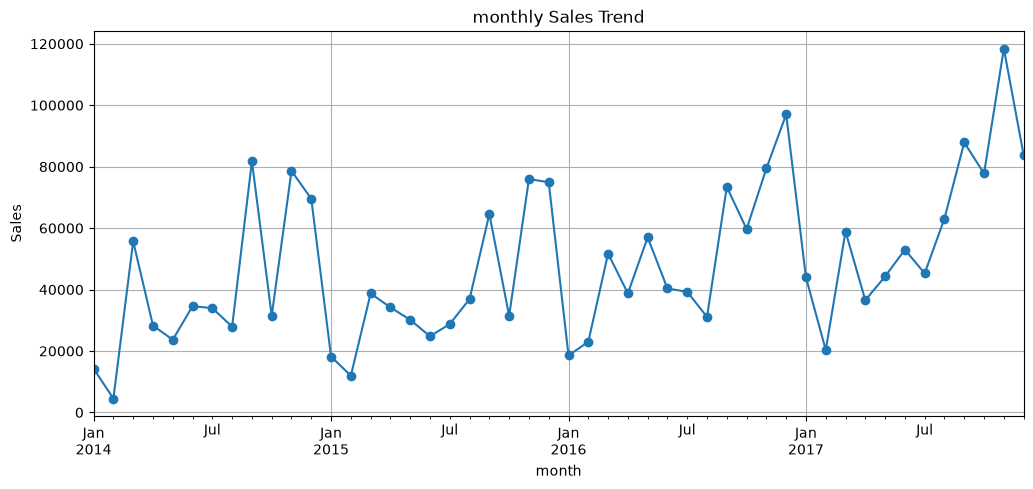

In [33]:
monthly_sales.plot(kind="line",figsize=(12,5),
                   marker="o")
plt.title("monthly Sales Trend")
plt.xlabel("month")
plt.ylabel("Sales")
plt.grid()
plt.show()

In [37]:
top_products=(df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10))
print(top_products)   

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [39]:
subcategory_profit=df.groupby("Sub-Category")["Profit"].sum().sort_values()
print(subcategory_profit)

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64


In [40]:
discount_analysis=df.groupby("Discount").agg({"Sales":'sum',"Profit":"sum"})
print(discount_analysis)

                 Sales       Profit
Discount                           
0.00      1.087908e+06  320987.6032
0.10      5.436935e+04    9029.1770
0.15      2.755852e+04    1418.9915
0.20      7.645944e+05   90337.3060
0.30      1.032267e+05  -10369.2774
0.32      1.449346e+04   -2391.1377
0.40      1.164178e+05  -23057.0504
0.45      5.484974e+03   -2493.1111
0.50      5.891854e+04  -20506.4281
0.60      6.644700e+03   -5944.6552
0.70      4.062028e+04  -40075.3569
0.80      1.696376e+04  -30539.0392


In [41]:
segment_sales=df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
print(segment_sales)

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


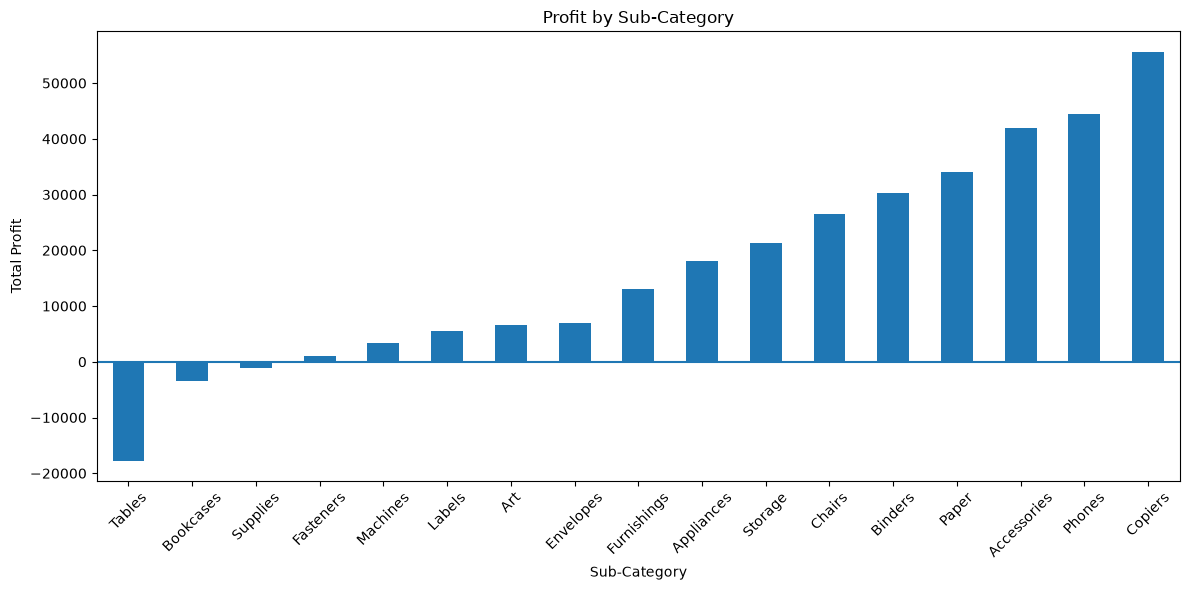

In [42]:
subcategory_profit.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.axhline(y=0)
plt.tight_layout()
plt.show()

In [43]:
import pandas as pd
import csv

df.to_csv(
    "myprojects.csv",
    index=False,
    encoding="utf-8",
    quoting=csv.QUOTE_ALL
)

In [45]:
!pip install mysql-connector-python
print(df.shape)
print(df.columns.tolist())

(9994, 22)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year-Month']


In [46]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Vyas@sql",
    database="superstore_analysis"
)

print("Connected successfully!")

Connected successfully!


In [47]:
print(df.shape)

(9994, 22)


In [49]:
cursor = conn.cursor()

cursor.execute("DROP TABLE IF EXISTS superstore_python")

cursor.execute("""
CREATE TABLE superstore_python (
    `Row ID` INT,
    `Order ID` VARCHAR(30),
    `Order Date` DATETIME,
    `Ship Date` DATETIME,
    `Ship Mode` VARCHAR(30),
    `Customer ID` VARCHAR(30),
    `Customer Name` VARCHAR(100),
    `Segment` VARCHAR(30),
    `Country` VARCHAR(100),
    `City` VARCHAR(100),
    `State` VARCHAR(100),
    `Postal Code` VARCHAR(20),
    `Region` VARCHAR(30),
    `Product ID` VARCHAR(30),
    `Category` VARCHAR(50),
    `Sub-Category` VARCHAR(50),
    `Product Name` VARCHAR(255),
    `Sales` DECIMAL(15,4),
    `Quantity` INT,
    `Discount` DECIMAL(5,2),
    `Profit` DECIMAL(15,4)
)
""")

conn.commit()

print("Table created successfully!")

Table created successfully!


In [51]:
# Remove Year-Month from SQL import
df_import = df.drop(
    columns=["Year-Month"],
    errors="ignore"
).copy()

print(df_import.shape)

(9994, 21)


In [52]:
df_import["Order Date"] = pd.to_datetime(
    df_import["Order Date"]
).dt.to_pydatetime()

df_import["Ship Date"] = pd.to_datetime(
    df_import["Ship Date"]
).dt.to_pydatetime()

In [53]:
import pandas as pd
import numpy as np

def convert_value(value):
    if pd.isna(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value

values = [
    tuple(convert_value(v) for v in row)
    for row in df_import.itertuples(index=False, name=None)
]

print("Prepared records:", len(values))

Prepared records: 9994


In [54]:
columns = [f"`{col}`" for col in df_import.columns]

sql = f"""
INSERT INTO superstore_python ({','.join(columns)})
VALUES ({','.join(['%s'] * len(columns))})
"""

cursor.executemany(sql, values)

conn.commit()

print("Imported records:", cursor.rowcount)

Imported records: 9994


In [55]:
cursor.execute("""
SELECT COUNT(*) FROM superstore_python
""")

print(cursor.fetchone())


(9994,)
